# Assignment 2: Local Features, Matching and Panorama Stitching
**MSAI6330 Computer Vision**

Goal: match local invariant features between two overlapping photos, estimate a homography with RANSAC, and stitch a panorama. We run the whole pipeline twice, once with SIFT and once with raw intensity patches, then compare.

| # | Section | Rubric marks |
|---|---|---|
| 1 | Feature detection | 10 |
| 2 | Feature description (SIFT and 11x11 patch) | 15 |
| 3-4 | Descriptor matching and putative match selection | 15 |
| 5 | Match visualization | 10 |
| 6 | Homography estimation with RANSAC | 20 |
| 7 | Panorama creation | 15 |
| 8 | Comparison and conclusion | 15 (shared with organization) |

**Conventions.** Image 1 is `left.jpg` and is the reference frame. Image 2 is `right.jpg`. The homography `H` maps image 2 coordinates into image 1 coordinates. Keypoints are stored as `N x 2` arrays of `(x, y)`.

OpenCV 5.0.0 | image size (height, width): (398, 800) (398, 800)


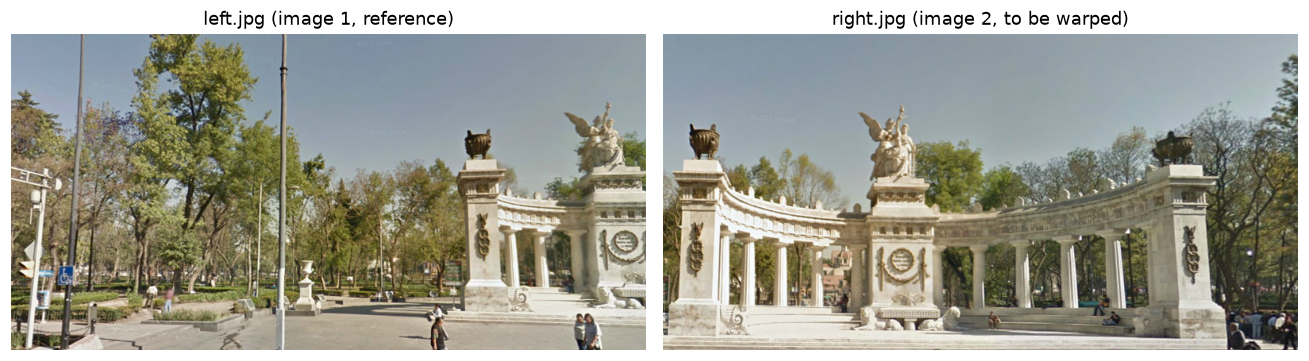

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.dpi"] = 110
random_generator = np.random.default_rng(0)          # fixed seed so RANSAC results are reproducible

IMAGE_DIRECTORY = Path("images")
left_bgr = cv2.imread(str(IMAGE_DIRECTORY / "left.jpg"))
right_bgr = cv2.imread(str(IMAGE_DIRECTORY / "right.jpg"))
assert left_bgr is not None and right_bgr is not None, "run the notebook from the repo root so images/ is found"

left = cv2.cvtColor(left_bgr, cv2.COLOR_BGR2RGB)
right = cv2.cvtColor(right_bgr, cv2.COLOR_BGR2RGB)
gray_left = cv2.cvtColor(left_bgr, cv2.COLOR_BGR2GRAY)
gray_right = cv2.cvtColor(right_bgr, cv2.COLOR_BGR2GRAY)
print("OpenCV", cv2.__version__, "| image size (height, width):", left.shape[:2], right.shape[:2])

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(left); axes[0].set_title("left.jpg (image 1, reference)")
axes[1].imshow(right); axes[1].set_title("right.jpg (image 2, to be warped)")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

## 1. Feature Detection
> **Requirement:** load the two images and detect feature points in both using Harris corners or blob detection.

**Method.** Harris corners from `cv2.goodFeaturesToTrack(..., useHarrisDetector=True)`. It scores every pixel with the Harris response, keeps the strongest local peaks (`qualityLevel` is a share of the best score, `minDistance` the spacing between points) and returns at most 1500 points.

**No smoothing first.** Harris already smooths (Sobel gradients summed over a window) and SIFT builds its own Gaussian scale space, so blurring beforehand would only remove detail.

**Result.** 777 points in the left image and 488 in the right. They sit on textured areas (foliage and the monument's stonework): the image gradient at the points is about 2.8 times the image average, and only 12% of the points lie in the top 30% of the image, where the sky is.


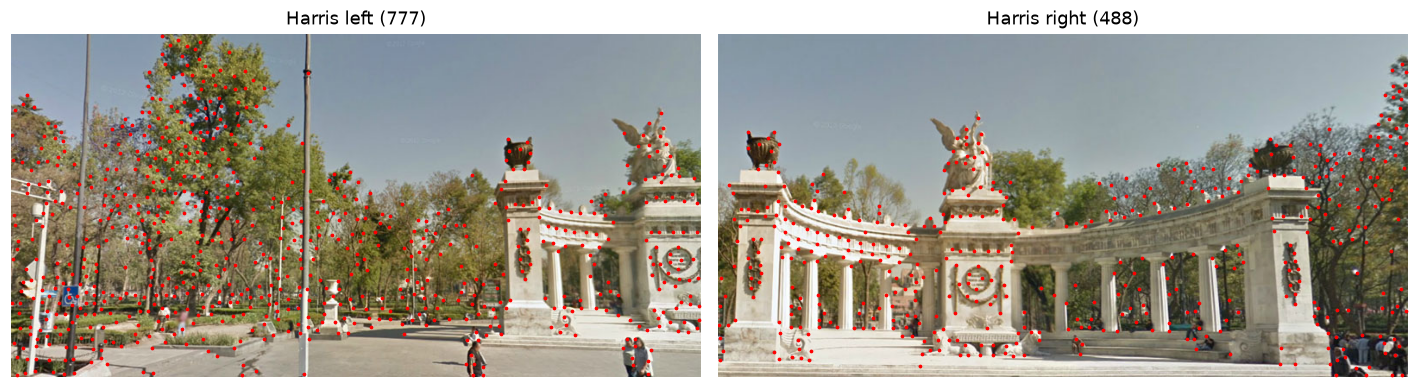

In [3]:
from matplotlib.pyplot import gray


def harris_keypoints(gray, harris_constant=0.04, block_size=3, relative_threshold=0.01, suppression_size=9, border=8, max_points=1500):
    response = cv2.cornerHarris(gray, blockSize=block_size, ksize=block_size, k=harris_constant)
    return cv2.goodFeaturesToTrack(gray, maxCorners=max_points, qualityLevel=relative_threshold, minDistance=suppression_size, useHarrisDetector=True, k=harris_constant).reshape(-1, 2), response

    
harris_points_left, response_left = harris_keypoints(gray_left)
harris_points_right, response_right = harris_keypoints(gray_right)
figure, axes = plt.subplots(1, 2, figsize=(13, 4))                    # one panel per image
for axis, image, points, title in [(axes[0], left, harris_points_left, "Harris left"), (axes[1], right, harris_points_right, "Harris right")]:
    axis.imshow(image)                                                # left/right are RGB, which is what imshow expects
    axis.scatter(points[:, 0], points[:, 1], s=6, c="r", linewidths=0)    # x values first, then y; s = marker size
    axis.set_title(f"{title} ({len(points)})"); axis.axis("off")
plt.tight_layout(); plt.show()


## 2. Feature Description
> **Requirement:** extract descriptors for the keypoints, testing (a) SIFT and (b) an intensity-based descriptor made from a local patch (e.g. 11x11) flattened to a 1D vector.

**SIFT.** 128 numbers per keypoint: a 4×4 grid of cells with an 8-bin histogram of gradient orientations each. Keypoints come from `sift.detect` and descriptors from `sift.compute`. It handles scale and rotation changes and is fairly robust to brightness changes.

**Patch.** The 11×11 pixels around each Harris point, flattened to 121 numbers and normalised (mean 0, standard deviation 1) so that brightness and contrast do not dominate. The image is padded with a mirrored border so points near the edge still get a full window. It has no scale or rotation handling.

**Result.** SIFT: 4408 and 3484 descriptors of 128 numbers. Patch: 777 and 488 descriptors of 121 numbers.


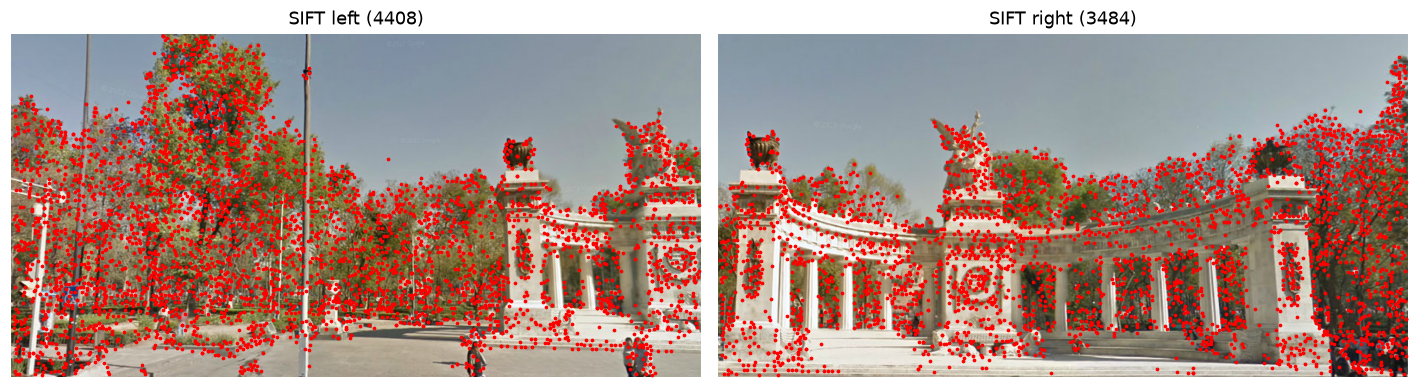

SIFT descriptor shape : (4408, 128) (3484, 128)
Patch descriptor shape: (777, 121) (488, 121)


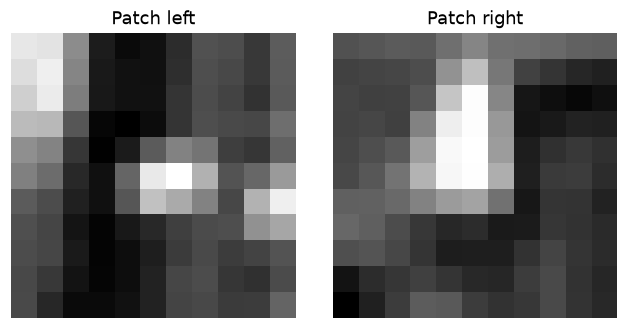

In [4]:
def sift_features(gray, contrastThreshold=0.04):
    sift = cv2.SIFT_create(contrastThreshold=contrastThreshold)
    keypoints = sift.detect(gray, None)                            # Task 1 part: where the keypoints are
    keypoints, descriptors = sift.compute(gray, keypoints)         # Task 2 part: one 128-number descriptor per keypoint (may drop keypoints too close to the border)
    points = np.float32([keypoint.pt for keypoint in keypoints])   # plain N x 2 array of (x, y)
    return keypoints, points, descriptors


def patch_descriptors(gray, points, size=11, normalize=True):
    # half the window width: an 11x11 window reaches 5 pixels out from its centre pixel
    radius = size // 2
    # surround the image with a 5 px mirrored border (as float32) so keypoints near the edge still get a full window
    padded = np.pad(gray, radius, mode="reflect").astype(np.float32)
    # for every keypoint (x, y), rounded to whole pixels: cut its 11x11 window and flatten it to 121 numbers, then stack all rows into an N x 121 table
    patches = np.array([padded[y:y + size, x:x + size].ravel() for x, y in np.rint(points).astype(int)])
    # per patch (row): subtract its mean and divide by its standard deviation so brightness and contrast differences do not matter (1e-6 avoids dividing by 0); skip this if normalize is False
    return (patches - patches.mean(1, keepdims=True)) / (patches.std(1, keepdims=True) + 1e-6) if normalize else patches


def plot_sift_keypoints(image_left, image_right, keypoints_left, keypoints_right):
    # one panel per image, with every SIFT keypoint drawn as a red dot
    figure, axes = plt.subplots(1, 2, figsize=(13, 4))
    for axis, image, keypoints, title in [(axes[0], image_left, keypoints_left, "SIFT left"), (axes[1], image_right, keypoints_right, "SIFT right")]:
        axis.imshow(image)
        axis.scatter([keypoint.pt[0] for keypoint in keypoints], [keypoint.pt[1] for keypoint in keypoints], s=6, c="r", linewidths=0)
        axis.set_title(f"{title} ({len(keypoints)})"); axis.axis("off")
    plt.tight_layout(); plt.show()


def plot_first_patches(descriptors_left, descriptors_right):
    # the first patch of each image, shown as an 11x11 picture
    figure, axes = plt.subplots(1, 2, figsize=(6, 3))
    for axis, descriptors, title in [(axes[0], descriptors_left, "Patch left"), (axes[1], descriptors_right, "Patch right")]:
        axis.imshow(descriptors[0].reshape(11, 11), cmap="gray")    # cmap="gray" so the 1-channel patch is not shown in false colour
        axis.set_title(title); axis.axis("off")
    plt.tight_layout(); plt.show()


# SIFT keypoints
keypoints_left, sift_points_left, sift_descriptors_left = sift_features(gray_left)
keypoints_right, sift_points_right, sift_descriptors_right = sift_features(gray_right)
plot_sift_keypoints(left, right, keypoints_left, keypoints_right)

# intensity patches around the Harris keypoints
patch_descriptors_left = patch_descriptors(gray_left, harris_points_left)
patch_descriptors_right = patch_descriptors(gray_right, harris_points_right)
print("SIFT descriptor shape :", sift_descriptors_left.shape, sift_descriptors_right.shape)
print("Patch descriptor shape:", patch_descriptors_left.shape, patch_descriptors_right.shape)
plot_first_patches(patch_descriptors_left, patch_descriptors_right)

## 3. Descriptor Matching
> **Requirement:** compute pairwise Euclidean distances between descriptors from the two images.

**Method.** Every descriptor of image 1 is compared with every descriptor of image 2 by Euclidean distance. Instead of a loop we use ‖a − b‖² = ‖a‖² + ‖b‖² − 2a·b, so one matrix product gives the whole table (rows: image 1 keypoints, columns: image 2 keypoints). It runs once per descriptor type, and both results are stored in the `data` dictionary.

**Result.** SIFT gives a 4408 × 3484 table and the patch descriptor a 777 × 488 table. The two live on different scales: the median SIFT distance is about 533, the median patch distance about 15.5. A single distance threshold could not serve both, which matters for Task 4.


SIFT  distance table: (4408, 3484), median 533.0
Patch distance table: (777, 488), median 15.5


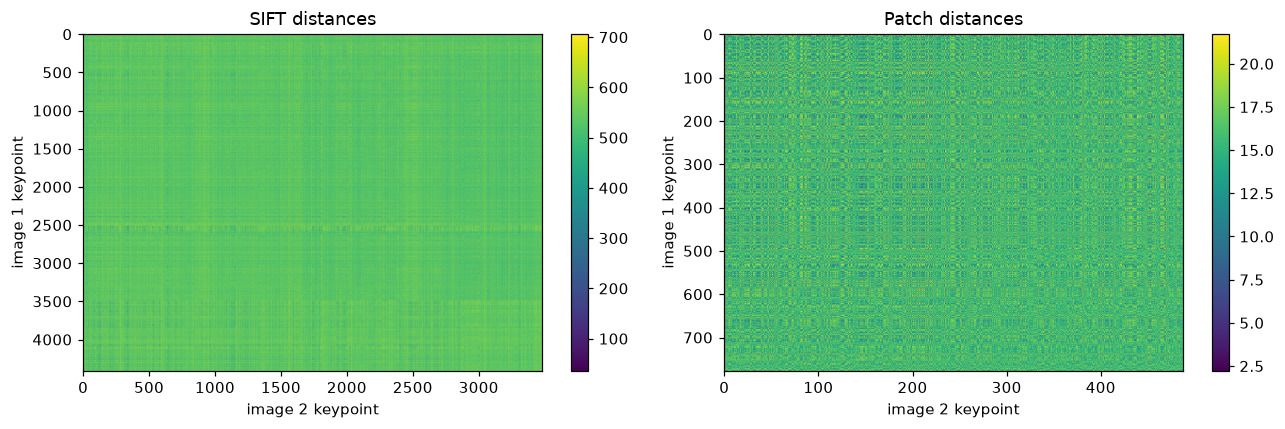

In [5]:
def pairwise_distances(descriptors_a, descriptors_b):
       squared_distances = (descriptors_a**2).sum(1)[:, None] + (descriptors_b**2).sum(1)[None, :] - 2 * descriptors_a @ descriptors_b.T
       distances = np.sqrt(np.maximum(squared_distances, 0))                 # maximum(...,0) removes tiny negatives caused by rounding
       return distances

# one entry per descriptor type, so the later tasks can loop over both
data = {
    "SIFT":  dict(points_left=sift_points_left,   points_right=sift_points_right,
                  descriptors_left=sift_descriptors_left,  descriptors_right=sift_descriptors_right),
    "Patch": dict(points_left=harris_points_left, points_right=harris_points_right,
                  descriptors_left=patch_descriptors_left, descriptors_right=patch_descriptors_right),
}
for name, entry in data.items():
    entry["distances"] = pairwise_distances(entry["descriptors_left"], entry["descriptors_right"])
    print(f"{name:5s} distance table: {entry['distances'].shape}, median {np.median(entry['distances']):.1f}")

# the distance tables as heat maps: rows = image 1 keypoints, columns = image 2 keypoints, dark = similar descriptors
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, (name, entry) in zip(axes, data.items()):
    heat_map = axis.imshow(entry["distances"], aspect="auto", cmap="viridis")
    axis.set_title(f"{name} distances"); axis.set_xlabel("image 2 keypoint"); axis.set_ylabel("image 1 keypoint")
    figure.colorbar(heat_map, ax=axis)
plt.tight_layout(); plt.show()



## 4. Putative Match Selection
> **Requirement:** select candidate matches using a threshold or the top matches with the smallest distances, and explain the strategy.

**Strategy: ratio test.** For each image 1 descriptor we find its closest and second-closest descriptor in image 2 and keep the pair only if `best distance < ratio × second distance`. A clear winner passes. An ambiguous pair, where two candidates are almost equally close (typical of repeated texture), is rejected.

**Why not the alternatives?** A fixed distance threshold needs a different number per descriptor, because SIFT distances are in the hundreds and normalised patch distances are around 10 to 20. Taking the top N smallest distances keeps N pairs however poor they are.

**Values.** 0.80 for SIFT (the usual value) and 0.90 for the patch descriptor. Patches are less distinctive, so at 0.80 only 61 pairs survive against 160 at 0.90, too few for RANSAC to work with. Wrong pairs are expected to remain, and RANSAC removes them in Task 6.

**Result.** SIFT: 246 putative matches. Patch: 160.


In [6]:
def select_matches(distances, ratio=0.8, mutual=True):
    nearest = np.argsort(distances, axis=1)[:, :2]   # axis=1 sorts each ROW; [:, :2] keeps the 2 closest columns (best, second best)
    rows = np.arange(len(distances))
    best_distance = distances[rows, nearest[:, 0]]   # distances to the best and second-best candidate
    second_distance = distances[rows, nearest[:, 1]]
    accepted = best_distance < ratio * second_distance   # ratio test. ratio: lower = stricter; about 0.8 is the usual value for SIFT
    pairs = np.stack([rows[accepted], nearest[accepted, 0]], axis=1)   # M x 2 array of (index in image 1, index in image 2)
    pair_distances = distances[rows[accepted], nearest[accepted, 0]]
    return pairs, pair_distances

RATIO_THRESHOLD = {"SIFT": 0.80, "Patch": 0.90}      # lower = stricter; patches are less distinctive, so they need a looser value
for name, entry in data.items():
    entry["pairs"], entry["pair_distances"] = select_matches(entry["distances"], RATIO_THRESHOLD[name])
    print(name, len(entry["pairs"]), "putative matches")


SIFT 246 putative matches
Patch 160 putative matches


## 5. Match Visualization
> **Requirement:** place the two images side by side and draw lines between corresponding keypoints.

**Method.** The two images are placed side by side on one canvas. A match is a line from a point in the left image to its partner in the right image. The right image starts after the left one, so the right x coordinate is shifted by the left image's width. At most 80 randomly chosen matches are drawn to keep the picture readable. The same function takes an inlier mask, which Task 6 uses to colour inliers green and outliers red.

**Observation.** Most lines run roughly parallel from the left image's monument to the right image's monument. Some lines cross at odd angles, so wrong matches remain. SIFT's lines are more consistent than the patch descriptor's.


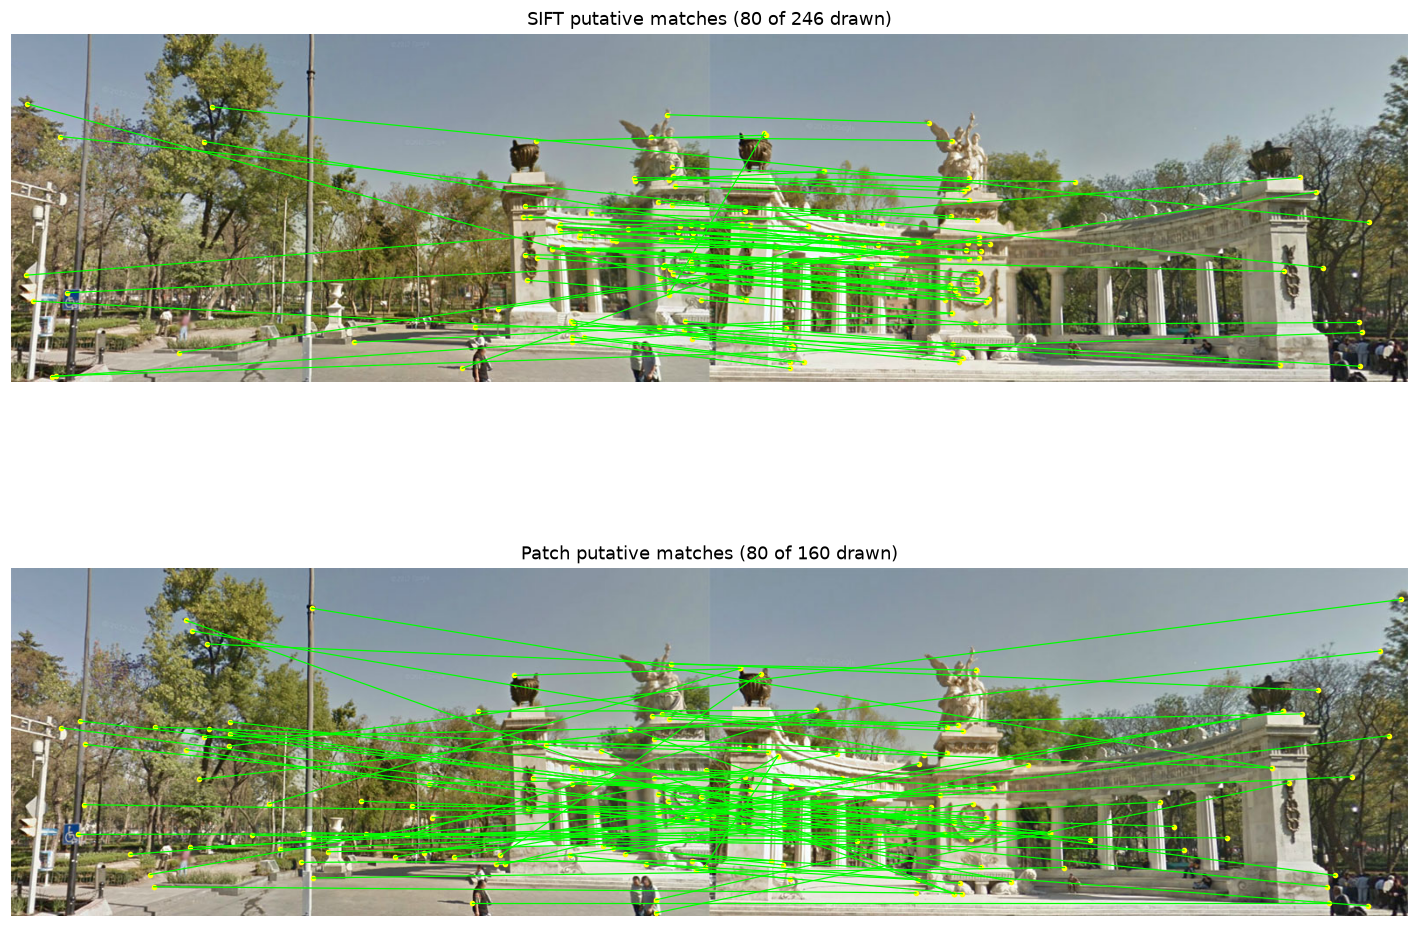

In [8]:
def draw_matches(image_left, image_right, points_left, points_right, pairs, axis, title, inlier_mask=None, max_lines=80):
    # place the two images side by side on one canvas (same height and dtype here)
    canvas = np.hstack([image_left, image_right])
    axis.imshow(canvas); axis.axis("off")
    # the right image starts after the left one, so its x coordinates are shifted by the left image's width
    x_offset = image_left.shape[1]
    # draw only a random subset when there are many matches, otherwise the picture is unreadable
    line_indices = np.arange(len(pairs))
    if len(line_indices) > max_lines:
        line_indices = np.sort(random_generator.choice(line_indices, max_lines, replace=False))
    for line_index in line_indices:
        left_index, right_index = pairs[line_index]                                  # pairs[k] = (index into points_left, index into points_right)
        is_inlier = True if inlier_mask is None else inlier_mask[line_index]         # green = inlier (or no mask given), red = outlier
        x_values = [points_left[left_index, 0], points_right[right_index, 0] + x_offset]
        y_values = [points_left[left_index, 1], points_right[right_index, 1]]       # y is unchanged
        axis.plot(x_values, y_values, color="lime" if is_inlier else "red", linewidth=0.8)
        axis.scatter(x_values, y_values, s=7, c="yellow")                            # mark both ends of the match
    axis.set_title(f"{title} ({len(line_indices)} of {len(pairs)} drawn)")


figure, axes = plt.subplots(2, 1, figsize=(13, 11))   # figsize in inches (width, height); tall because the canvas is wide
for axis, (name, entry) in zip(axes, data.items()):
    draw_matches(left, right, entry["points_left"], entry["points_right"], entry["pairs"], axis, f"{name} putative matches")
plt.tight_layout(); plt.show()

## 6. Homography Estimation Using RANSAC
> **Requirement:** implement RANSAC for the homography; report the number of inliers, the average squared reprojection error of the inliers, and a visualization of the inlier correspondences.

_TODO: briefly explain your method and what you observe in the results._

In [ ]:
def apply_homography(homography, points):
    """TODO: apply a 3x3 homography to Nx2 points (homogeneous coordinates, then divide by w)."""
    # Option A, by hand:
    #   projected = np.c_[points, np.ones(len(points))] @ homography.T   # append a 1 to every (x, y), multiply by the homography -> columns are (x', y', w')
    #   return projected[:, :2] / projected[:, 2:3]                      # divide by w'. w' can be ~0 for a bad homography -> inf/nan, that is fine, such points just count as outliers
    # Option B, OpenCV:
    #   cv2.perspectiveTransform(points.reshape(-1, 1, 2).astype(np.float32),   # input MUST have shape (N, 1, 2) and be float
    #                            homography).reshape(-1, 2)                      # does the divide-by-w for you
    raise NotImplementedError


def squared_reprojection_error(homography, source_points, destination_points):
    """TODO: squared Euclidean distance between homography*source_points and destination_points, one value per point."""
    # ((apply_homography(homography, source_points) - destination_points) ** 2).sum(axis=1)   # axis=1 adds dx^2 + dy^2 per point. Do NOT take the square root
    raise NotImplementedError


def ransac_homography(source_points, destination_points, num_iterations=3000, epsilon=3.0, random_generator=random_generator):
    """TODO: RANSAC loop. Sample 4 pairs -> cv2.getPerspectiveTransform -> count inliers
    (squared error < epsilon**2) -> keep the best -> refit on all inliers with cv2.findHomography(..., 0).
    Return (homography, inlier_mask, squared_errors)."""
    # sample = random_generator.choice(len(source_points), 4, replace=False)   # 4 DISTINCT random match indices (replace=False matters)
    # homography = cv2.getPerspectiveTransform(
    #         source_points[sample].astype(np.float32),        # source_points: exactly 4 x 2, float32 (OpenCV rejects float64 here). Points in image 2
    #         destination_points[sample].astype(np.float32))   # destination_points: the 4 matching points in image 1. Returns the homography source -> destination
    #   wrap it in try/except cv2.error: degenerate samples (e.g. 3 collinear points) can fail
    # inliers = squared_reprojection_error(homography, source_points, destination_points) < epsilon ** 2   # epsilon is in PIXELS (3 is a reasonable start); compare against epsilon squared
    # keep the hypothesis with the largest inliers.sum()
    # homography, _ = cv2.findHomography(
    #         source_points[best_inliers], destination_points[best_inliers],   # all inlier points of the best hypothesis
    #         0)                                                                # method 0 = ordinary least squares, NO RANSAC (you already did that)
    # Do not use cv2.findHomography(..., cv2.RANSAC, ransacReprojThreshold) AS your RANSAC; it is fine as a cross-check of your inlier count.
    # num_iterations: how many random samples to try. More iterations = safer with a low inlier ratio (slide 93).
    raise NotImplementedError


# TODO: run RANSAC for SIFT and Patch matches (source_points = image-2 points, destination_points = image-1 points)
#   source_points = entry["points_right"][pairs[:, 1]]        # column 1 of pairs indexes image 2
#   destination_points = entry["points_left"][pairs[:, 0]]    # column 0 of pairs indexes image 1
# TODO: report the inlier count and the mean squared reprojection error of the inliers
#   inliers.sum()                        # inlier count
#   errors[inliers].mean()               # mean SQUARED error over the inliers only
# TODO: visualize the inlier correspondences
#   draw_matches(..., entry["pairs"][inliers], ...)   # boolean mask selects the inlier rows; reuse your function from Task 5

## 7. Panorama Creation
> **Requirement:** create a new image big enough to hold the panorama and composite the two images into it (average in the overlap, or use pixels from one image).

_TODO: briefly explain your method and what you observe in the results._

In [ ]:
def make_panorama(image_reference, image_moving, homography, max_pixels=40_000_000):
    """TODO: 1) transform the corners of image_moving with the homography, 2) bounding box with image_reference's corners,
    3) translation matrix so the box starts at (0, 0), 4) cv2.warpPerspective(image_moving, translation @ homography, size),
    5) paste image_reference at the offset, 6) average (or copy one image) where both have pixels.
    Return the panorama, or None if the homography is unusable."""
    # corners_moving = np.float32([[0, 0], [moving_width, 0], [moving_width, moving_height], [0, moving_height]])   # corners of image 2 as (x, y); width/height = image_moving.shape[1], [0]
    # warped_corners = apply_homography(homography, corners_moving)   # where those corners land in image 1's frame
    # all_corners = np.vstack([corners_reference, warped_corners])    # corners_reference: same 4 corners for image_reference
    # x_min, y_min = np.floor(all_corners.min(0)).astype(int)         # bounding box; floor/ceil so nothing is clipped
    # x_max, y_max = np.ceil(all_corners.max(0)).astype(int)
    # translation = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], float)   # moves negative coordinates into view
    # warped = cv2.warpPerspective(
    #         image_moving,
    #         translation @ homography,                      # 3x3 matrix, homography first then the shift (matrix order is right-to-left)
    #         (x_max - x_min, y_max - y_min))                # dsize = (WIDTH, HEIGHT): the reverse of numpy's (rows, cols)
    #     flags=cv2.INTER_LINEAR is the default (interpolation used for the backward warp); keep it for the image
    # mask_warped = cv2.warpPerspective(np.full(image_moving.shape[:2], 255, np.uint8), translation @ homography, (canvas_width, canvas_height),
    #         flags=cv2.INTER_NEAREST) > 0                   # which output pixels hold real image-2 data; NEAREST keeps the mask clean 0/255
    # canvas[-y_min : -y_min + reference_height, -x_min : -x_min + reference_width] = image_reference   # paste image 1 at the shifted position (rows = y, cols = x)
    # Blend where BOTH images have pixels:
    #   panorama[overlap] = 0.5 * reference[overlap].astype(np.float32) + 0.5 * warped[overlap].astype(np.float32)   # float first, uint8 sums would wrap around
    #   (cv2.addWeighted(first, 0.5, second, 0.5, 0) does the same weighted average; its last arg is a constant added to every pixel)
    # Convert back with np.clip(panorama, 0, 255).astype(np.uint8) before imshow.
    # max_pixels guards against a nonsense homography producing a gigantic canvas: if canvas_width * canvas_height > max_pixels, return None.
    raise NotImplementedError


# TODO: build and show the panorama for both descriptor types
#   plt.imshow(panorama)                # the panorama is RGB because the inputs left / right are RGB

## 8. Comparison: SIFT vs Intensity-Based Descriptor
> **Requirement:** compare the descriptors by number of putative matches, number of RANSAC inliers, reprojection error and final panorama quality.

_TODO: briefly explain your method and what you observe in the results._

In [ ]:
# TODO: print a comparison table: putative matches, RANSAC inliers, inlier ratio, mean squared
#       reprojection error, for SIFT and Patch.
#   Nothing new to call: gather len(entry["pairs"]), entry["inliers"].sum(), entry["inliers"].mean(), and the mean error.
#   print(f"{'SIFT':>10}{value:>8}")   # f-string alignment: '>10' right-aligns in a field 10 characters wide, handy for table columns
# TODO: show both panoramas one above the other.
#   figure, axes = plt.subplots(2, 1, figsize=(13, 10))   # 2 rows, 1 column
#   axes[0].imshow(panorama_sift); axes[0].axis("off")    # if a panorama is None (failed homography), show text instead of crashing

### Extra experiment: does smoothing help the patch descriptor?
> **Requirement:** (optional, not in the assignment brief) check whether Gaussian smoothing removes noise that hurts the raw patch descriptor.

_TODO: explain what you tried and what you observed. Hint: Harris and SIFT already smooth internally (Sobel + window, Gaussian scale space); the raw patch is the only unsmoothed descriptor._

In [ ]:
# TODO (optional extra): does Gaussian smoothing before cutting patches help the patch descriptor?
# Idea: wrap Tasks 2 to 6 for the patch descriptor in a function of the blur strength sigma and compare.
#   kernel_size = 2 * int(round(3 * sigma)) + 1   # kernel size: odd, about 6 sigma wide
#   blurred = cv2.GaussianBlur(
#       gray_left,                                # the gray image (blur BOTH images with the same sigma)
#       (kernel_size, kernel_size),               # ksize: (width, height), both odd
#       sigma)                                    # sigmaX: blur strength; try 0.5, 1, 1.5, 2, 3
#   patch_descriptors_left = patch_descriptors(blurred, harris_points_left)   # keep Harris detection on the original image first
#   random_generator=np.random.default_rng(0)     # use the same seed for every sigma so the runs are comparable
# Report putative matches, inliers, inlier ratio and mean squared error per sigma (a small table or a plot).

## Conclusion
> **Requirement:** a short conclusion summarizing the main findings.

_TODO: write 5-8 sentences: which descriptor did better on each measure and why (invariance vs discriminability), what the panorama looks like, and one limitation._